In [2]:
# %%
import os
from pathlib import Path

_tok = Path.home() / ".kaggle" / "access_token"
if _tok.exists():
    os.environ["KAGGLE_API_TOKEN"] = _tok.read_text().strip()
    print("Token loaded from ~/.kaggle/access_token")
else:
    print("No token file found — create it first.")

Token loaded from ~/.kaggle/access_token


In [3]:
# %%
import sys, zipfile, tarfile, hashlib, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)

DATA   = Path("data");      DATA.mkdir(exist_ok=True)
FIGDIR = Path("figures");   FIGDIR.mkdir(exist_ok=True)
OUT    = Path("artifacts"); OUT.mkdir(exist_ok=True)

COMP = "challenges-in-representation-learning-facial-expression-recognition-challenge"
MIRRORS = ["deadskull7/fer2013", "msambare/fer2013"]

EMOTION_MAP = {0: "angry", 1: "disgust", 2: "fear", 3: "happy",
               4: "sad", 5: "surprise", 6: "neutral"}

print("Working dir:", Path.cwd())

Working dir: /path/to/Documents


In [7]:
# %%
import kagglehub

def extract_all(root: Path):
    """Recursively unpack every .zip / .tar.gz found under root."""
    for _ in range(3):
        found = False
        for f in list(root.rglob("*")):
            if f.suffix == ".zip":
                with zipfile.ZipFile(f) as z: z.extractall(f.parent)
                f.unlink(); found = True
            elif f.name.endswith((".tar.gz", ".tgz")):
                with tarfile.open(f) as t: t.extractall(f.parent)
                f.unlink(); found = True
        if not found:
            break

source_used = None
try:
    cache = Path(kagglehub.competition_download(COMP))
    print("kagglehub cache:", cache)
    for f in cache.rglob("*"):
        if f.is_file():
            shutil.copy2(f, DATA / f.name)
    extract_all(DATA)
    source_used = f"kaggle competition: {COMP}"
except Exception as e:
    print(f"Competition download failed ({type(e).__name__}: {e})")
    print("Falling back to dataset mirror...\n")
    for slug in MIRRORS:
        try:
            p = Path(kagglehub.dataset_download(slug))
            for f in p.rglob("*"):
                if f.is_file():
                    shutil.copy2(f, DATA / f.name)
            extract_all(DATA)
            source_used = f"kaggle dataset mirror: {slug}"
            break
        except Exception as e2:
            print(f"  {slug} failed: {e2}")

print("\nSource used:", source_used)
print("Files in data/:")
for f in sorted(DATA.rglob("*")):
    if f.is_file():
        print(f"  {f.relative_to(DATA)}  ({f.stat().st_size/1e6:.1f} MB)")

Competition download failed (KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://kaggle.com/competitions/challenges-in-representation-learning-facial-expression-recognition-challenge
Please make sure you are authenticated and have accepted the competition rules which can be found at this location: https://kaggle.com/competitions/challenges-in-representation-learning-facial-expression-recognition-challenge/rules)
Falling back to dataset mirror...



100%|██████████| 96.6M/96.6M [00:07<00:00, 14.1MB/s]

Extracting files...



Source used: kaggle dataset mirror: deadskull7/fer2013
Files in data/:
  fer2013.csv  (301.1 MB)


In [6]:
!pip install kagglehub

In [8]:
# %%
csvs = [f for f in DATA.rglob("*.csv")
        if "fer" in f.name.lower() and "submission" not in f.name.lower()]
if not csvs:
    csvs = [f for f in DATA.rglob("*.csv") if f.stat().st_size > 10_000_000]

assert csvs, (f"No fer2013 CSV under {DATA.resolve()}. Found: "
              f"{[str(p.relative_to(DATA)) for p in DATA.rglob('*') if p.is_file()]}")

CSV = max(csvs, key=lambda f: f.stat().st_size)
print(f"Using: {CSV}  ({CSV.stat().st_size/1e6:.1f} MB)")

raw = pd.read_csv(CSV)
print("Columns:", list(raw.columns))
print("Rows:", f"{len(raw):,}")
raw.head(3)

Using: data/fer2013.csv  (301.1 MB)
Columns: ['emotion', 'pixels', 'Usage']
Rows: 35,887


,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training


In [9]:
# %%
raw.columns = [c.strip().lower() for c in raw.columns]
assert {"emotion", "pixels"}.issubset(raw.columns), f"Unexpected schema: {list(raw.columns)}"

if "usage" not in raw.columns:
    print("WARNING: no 'usage' column — this source dropped the official split. "
          "You'll build a stratified split in Step 2.")
    raw["usage"] = "Training"

vals = np.stack(raw["pixels"].map(lambda s: np.array(s.split(), dtype=np.uint8)).values)
assert vals.shape[1] == 48 * 48, f"Expected 2304 pixels/row, got {vals.shape[1]}"

X = vals.reshape(-1, 48, 48)
y = raw["emotion"].astype(int).values
usage = raw["usage"].values

print(f"X: {X.shape} {X.dtype}   range [{X.min()}, {X.max()}]")
print(f"y: {y.shape}  classes {sorted(set(y))}")

manifest = pd.DataFrame({
    "index":    np.arange(len(y)),
    "label_id": y,
    "label":    [EMOTION_MAP[i] for i in y],
    "usage":    usage,
})
print("\n", pd.crosstab(manifest["label"], manifest["usage"]))

X: (35887, 48, 48) uint8   range [0, 255]
y: (35887,)  classes [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

 usage     PrivateTest  PublicTest  Training
label                                      
angry             491         467      3995
disgust            55          56       436
fear              528         496      4097
happy             879         895      7215
neutral           626         607      4965
sad               594         653      4830
surprise          416         415      3171


In [10]:
# %%
report = {}

stds = X.reshape(len(X), -1).std(axis=1)
report["near_constant_images"] = int((stds < 1.0).sum())
print(f"Near-constant (blank/corrupt) images: {report['near_constant_images']}")

hashes = np.array([hashlib.md5(img.tobytes()).hexdigest() for img in X])
manifest["hash"] = hashes
dup_counts = pd.Series(hashes).value_counts()
report["duplicate_rows"] = int(dup_counts[dup_counts > 1].sum() - (dup_counts > 1).sum())
print(f"Exact-duplicate images: {report['duplicate_rows']}")

span = manifest.groupby("hash")["usage"].nunique()
report["hashes_spanning_splits"] = int((span > 1).sum())
print(f"Identical images in more than one split: {report['hashes_spanning_splits']}")
if report["hashes_spanning_splits"]:
    print("  -> real leakage. Document it; de-dup in Step 2.")

conflict = manifest.groupby("hash")["label_id"].nunique()
report["hashes_with_conflicting_labels"] = int((conflict > 1).sum())
print(f"Identical images with conflicting labels: {report['hashes_with_conflicting_labels']}")

manifest.to_csv(OUT / "manifest.csv", index=False)

Near-constant (blank/corrupt) images: 13
Exact-duplicate images: 1853
Identical images in more than one split: 557
  -> real leakage. Document it; de-dup in Step 2.
Identical images with conflicting labels: 57


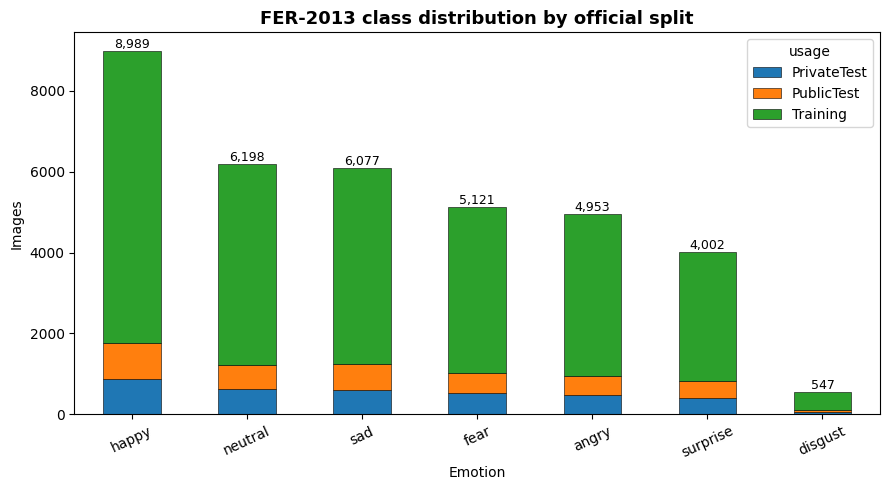

Imbalance ratio        : 16.4:1  (happy vs disgust)
Majority-class baseline: 0.2505   <- every model must beat this
Random-guess baseline  : 0.1429


In [11]:
# %%
ct = pd.crosstab(manifest["label"], manifest["usage"])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5))
ct.plot(kind="bar", stacked=True, ax=ax, edgecolor="black", linewidth=0.4)
ax.set_title("FER-2013 class distribution by official split", fontsize=13, weight="bold")
ax.set_xlabel("Emotion"); ax.set_ylabel("Images")
ax.tick_params(axis="x", rotation=25)
for i, t in enumerate(ct.sum(axis=1)):
    ax.text(i, t, f"{t:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(FIGDIR / "01_class_distribution.png", dpi=150); plt.show()

totals = ct.sum(axis=1)
imb = totals.max() / totals.min()
maj = totals.max() / totals.sum()
print(f"Imbalance ratio        : {imb:.1f}:1  ({totals.idxmax()} vs {totals.idxmin()})")
print(f"Majority-class baseline: {maj:.4f}   <- every model must beat this")
print(f"Random-guess baseline  : {1/len(totals):.4f}")

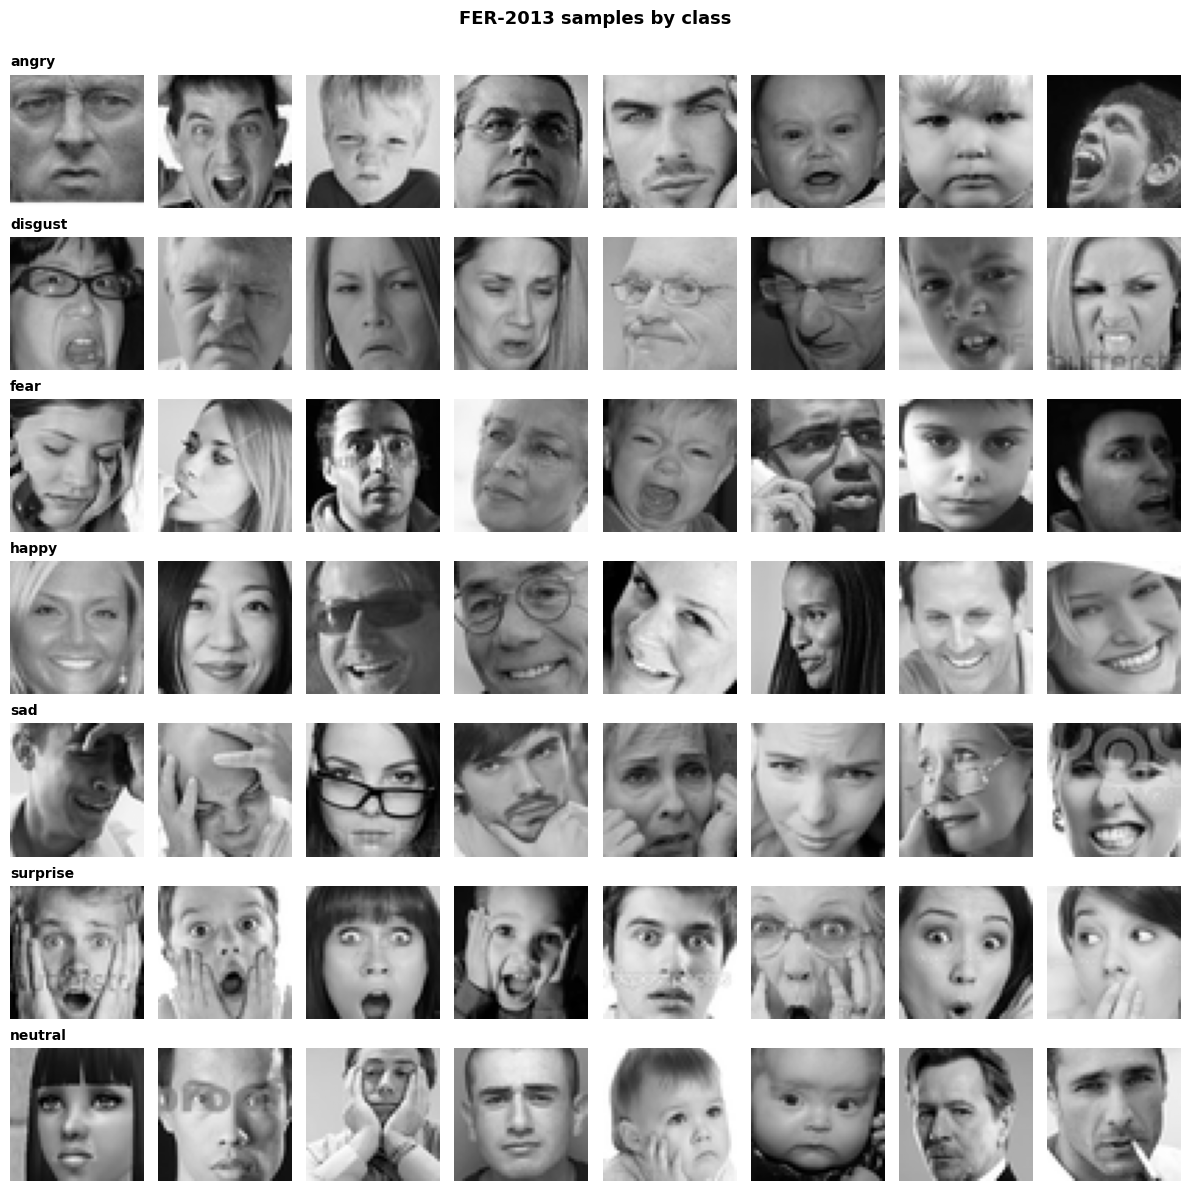

In [12]:
# %%
classes = [EMOTION_MAP[i] for i in sorted(EMOTION_MAP)]
n_show = 8
fig, axes = plt.subplots(len(classes), n_show, figsize=(n_show*1.5, len(classes)*1.7))
for r, cls in enumerate(classes):
    idx = manifest.index[manifest["label"] == cls]
    pick = np.random.choice(idx, size=min(n_show, len(idx)), replace=False)
    for c in range(n_show):
        ax = axes[r, c]; ax.axis("off")
        if c < len(pick):
            ax.imshow(X[pick[c]], cmap="gray", vmin=0, vmax=255)
        if c == 0:
            ax.set_title(cls, loc="left", fontsize=10, weight="bold")
fig.suptitle("FER-2013 samples by class", y=1.0, fontsize=13, weight="bold")
plt.tight_layout(); plt.savefig(FIGDIR / "02_sample_grid.png", dpi=150, bbox_inches="tight"); plt.show()

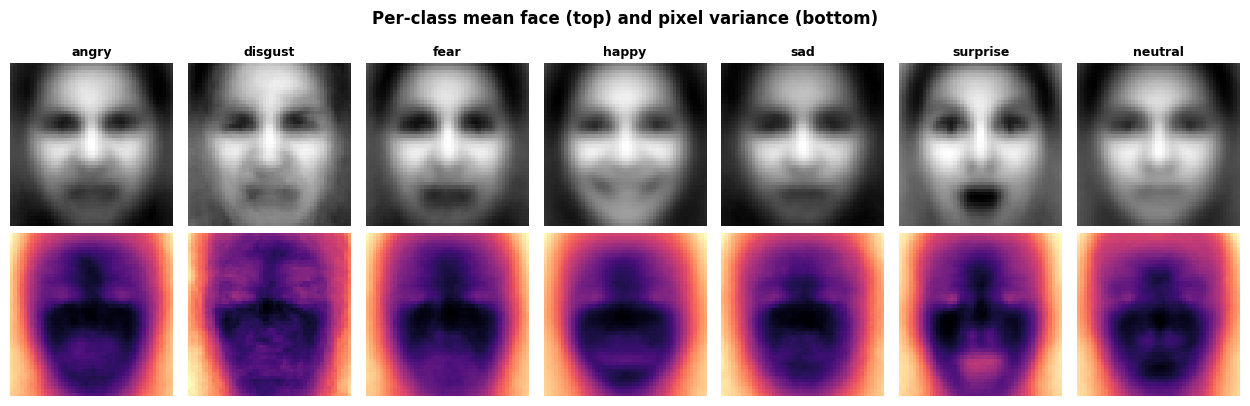

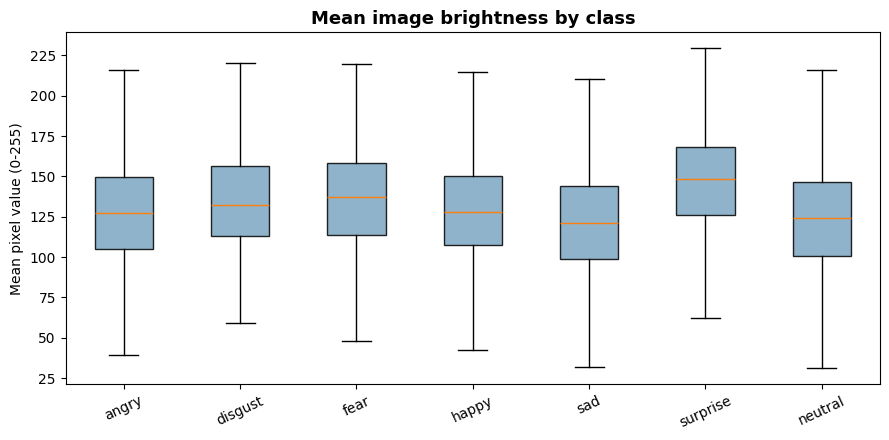

In [13]:
# %%
fig, axes = plt.subplots(2, len(classes), figsize=(len(classes)*1.8, 4.2))
for c, cls in enumerate(classes):
    sel = X[manifest["label"].values == cls]
    axes[0, c].imshow(sel.mean(axis=0), cmap="gray"); axes[0, c].axis("off")
    axes[0, c].set_title(cls, fontsize=9, weight="bold")
    axes[1, c].imshow(sel.std(axis=0), cmap="magma"); axes[1, c].axis("off")
fig.suptitle("Per-class mean face (top) and pixel variance (bottom)", fontsize=12, weight="bold")
plt.tight_layout(); plt.savefig(FIGDIR / "03_mean_faces.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
data = [X[manifest["label"].values == c].reshape(-1, 2304).mean(axis=1) for c in classes]
bp = ax.boxplot(data, labels=classes, patch_artist=True, showfliers=False)
for b in bp["boxes"]: b.set_facecolor("#7aa6c2"); b.set_alpha(0.85)
ax.set_title("Mean image brightness by class", fontsize=13, weight="bold")
ax.set_ylabel("Mean pixel value (0-255)"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(FIGDIR / "04_brightness_by_class.png", dpi=150); plt.show()

In [14]:
# %%
np.savez_compressed(OUT / "fer2013.npz", X=X, y=y,
                    usage=usage.astype(str), classes=np.array(classes))

summary = {
    "source": source_used,
    "csv_path": str(CSV),
    "n_images": int(len(X)),
    "image_shape": [48, 48],
    "n_classes": len(classes),
    "classes": classes,
    "split_counts": {k: int(v) for k, v in pd.Series(usage).value_counts().items()},
    "class_counts": {k: int(v) for k, v in totals.items()},
    "imbalance_ratio": round(float(imb), 2),
    "majority_baseline": round(float(maj), 4),
    "random_baseline": round(1/len(classes), 4),
    "integrity": report,
}
with open(OUT / "data_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print(f"\nCached: {OUT/'fer2013.npz'}  ({(OUT/'fer2013.npz').stat().st_size/1e6:.1f} MB)")

{
  "source": "kaggle dataset mirror: deadskull7/fer2013",
  "csv_path": "data/fer2013.csv",
  "n_images": 35887,
  "image_shape": [
    48,
    48
  ],
  "n_classes": 7,
  "classes": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
  ],
  "split_counts": {
    "Training": 28709,
    "PublicTest": 3589,
    "PrivateTest": 3589
  },
  "class_counts": {
    "happy": 8989,
    "neutral": 6198,
    "sad": 6077,
    "fear": 5121,
    "angry": 4953,
    "surprise": 4002,
    "disgust": 547
  },
  "imbalance_ratio": 16.43,
  "majority_baseline": 0.2505,
  "random_baseline": 0.1429,
  "integrity": {
    "near_constant_images": 13,
    "duplicate_rows": 1853,
    "hashes_spanning_splits": 557,
    "hashes_with_conflicting_labels": 57
  }
}

Cached: artifacts/fer2013.npz  (78.3 MB)


Loaded: 35,887 images
start                                  remaining  35,887

A. blank/near-constant       -    13   remaining  35,874
B. contradictory labels      -   148   remaining  35,726
C. leaked train copies       -   649   remaining  35,077
D. PublicTest/PrivateTest overlap -    43   remaining  35,034
E. within-split duplicates   - 1,058   remaining  33,976

Post-clean verification (all should be 0):
  duplicate_hashes_remaining     0
  hashes_spanning_splits         0
  conflicting_labels             0
  near_constant                  0

           before  after  removed  pct_removed
angry       4953   4717      236         4.76
disgust      547    458       89        16.27
fear        5121   4802      319         6.23
happy       8989   8794      195         2.17
sad         6077   5912      165         2.72
surprise    4002   3248      754        18.84
neutral     6198   6045      153         2.47

Split sizes after cleaning:
Training       26911
PrivateTest     3557
Publi

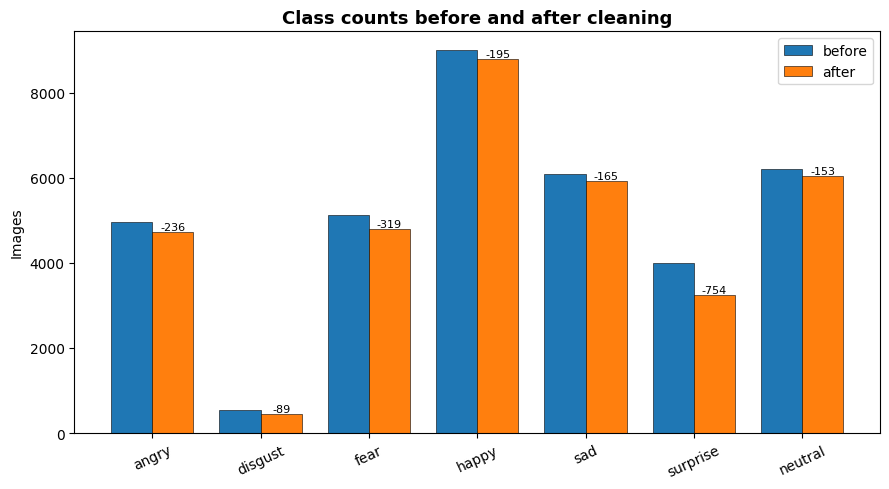


Saved: artifacts/fer2013_clean.npz
Removed 1,911 of 35,887 (5.33%)


In [15]:
# %% [markdown]
# # Step 1b — Cleaning
# Removes blanks, contradictory labels, cross-split leakage, and duplicates.
# Writes artifacts/fer2013_clean.npz and a cleaning ledger for the report.

# %%
import numpy as np, pandas as pd, hashlib, json
from pathlib import Path
import matplotlib.pyplot as plt

OUT    = Path("artifacts")
FIGDIR = Path("figures")

d = np.load(OUT / "fer2013.npz", allow_pickle=False)
X, y, usage, classes = d["X"], d["y"], d["usage"].astype(str), list(d["classes"])
print(f"Loaded: {X.shape[0]:,} images")

df = pd.DataFrame({
    "idx":   np.arange(len(y)),
    "label": y,
    "usage": usage,
    "hash":  [hashlib.md5(im.tobytes()).hexdigest() for im in X],
    "std":   X.reshape(len(X), -1).std(axis=1),
})

ledger = []
def log(step, removed, remaining, why):
    ledger.append({"step": step, "removed": int(removed),
                   "remaining": int(remaining), "rationale": why})
    print(f"{step:<28} -{removed:>6,}   remaining {remaining:>7,}")

keep = pd.Series(True, index=df.index)
print(f"{'start':<28} {'':>7}   remaining {len(df):>7,}\n")

# %%
# --- A. Blank / near-constant images -----------------------------------
mask = df["std"] < 1.0
keep &= ~mask
log("A. blank/near-constant", mask.sum(), keep.sum(),
    "no facial information; pure noise for the optimizer")

# --- B. Contradictory labels -------------------------------------------
# Identical pixels labelled differently. We cannot know which is correct,
# so every copy is discarded rather than guessing.
conflict_hashes = df.groupby("hash")["label"].nunique()
conflict_hashes = set(conflict_hashes[conflict_hashes > 1].index)
mask = df["hash"].isin(conflict_hashes) & keep
keep &= ~mask
log("B. contradictory labels", mask.sum(), keep.sum(),
    "same image, different label; ground truth unrecoverable")

# --- C. Cross-split leakage: train copies ------------------------------
# Drop from Training only. Test sets stay intact so results remain
# comparable to published FER-2013 benchmarks.
sub = df[keep]
test_hashes = set(sub.loc[sub["usage"] != "Training", "hash"])
mask = (df["usage"] == "Training") & df["hash"].isin(test_hashes) & keep
keep &= ~mask
log("C. leaked train copies", mask.sum(), keep.sum(),
    "image also present in a test split; would inflate test accuracy")

# --- D. Cross-split leakage: PublicTest vs PrivateTest -----------------
# PrivateTest is the canonical final benchmark, so it is preserved whole.
sub = df[keep]
priv = set(sub.loc[sub["usage"] == "PrivateTest", "hash"])
mask = (df["usage"] == "PublicTest") & df["hash"].isin(priv) & keep
keep &= ~mask
log("D. PublicTest/PrivateTest overlap", mask.sum(), keep.sum(),
    "validation and final test must not share images")

# --- E. Within-split duplicates ----------------------------------------
sub = df[keep]
dup_idx = sub[sub.duplicated(subset=["usage", "hash"], keep="first")]["idx"]
mask = df["idx"].isin(dup_idx) & keep
keep &= ~mask
log("E. within-split duplicates", mask.sum(), keep.sum(),
    "repeated images silently reweight the loss")

# %%
# --- Verify the cleaning actually worked -------------------------------
final = df[keep]
checks = {
    "duplicate_hashes_remaining": int(final.duplicated(subset=["hash"]).sum()),
    "hashes_spanning_splits":     int((final.groupby("hash")["usage"].nunique() > 1).sum()),
    "conflicting_labels":         int((final.groupby("hash")["label"].nunique() > 1).sum()),
    "near_constant":              int((final["std"] < 1.0).sum()),
}
print("\nPost-clean verification (all should be 0):")
for k, v in checks.items():
    print(f"  {k:<30} {v}")
assert all(v == 0 for v in checks.values()), "cleaning did not fully resolve issues"

# %%
# --- Save ---------------------------------------------------------------
sel = final["idx"].values
Xc, yc, uc = X[sel], y[sel], usage[sel]

np.savez_compressed(OUT / "fer2013_clean.npz",
                    X=Xc, y=yc, usage=uc.astype(str), classes=np.array(classes))

before = pd.Series(y).map(lambda i: classes[i]).value_counts()
after  = pd.Series(yc).map(lambda i: classes[i]).value_counts()
comp = pd.DataFrame({"before": before, "after": after}).fillna(0).astype(int)
comp["removed"] = comp["before"] - comp["after"]
comp["pct_removed"] = (comp["removed"] / comp["before"] * 100).round(2)
comp = comp.loc[[c for c in classes]]
print("\n", comp)

print("\nSplit sizes after cleaning:")
print(pd.Series(uc).value_counts())

# class weights for the imbalance, computed on cleaned training data only
tr = yc[uc == "Training"]
counts = np.bincount(tr, minlength=len(classes))
weights = len(tr) / (len(classes) * counts)
class_weight = {i: round(float(w), 4) for i, w in enumerate(weights)}
print("\nClass weights (Step 3):", class_weight)

pd.DataFrame(ledger).to_csv(OUT / "cleaning_ledger.csv", index=False)
comp.to_csv(OUT / "class_counts_before_after.csv")

clean_summary = {
    "n_before": int(len(X)),
    "n_after": int(len(Xc)),
    "n_removed": int(len(X) - len(Xc)),
    "pct_removed": round((len(X) - len(Xc)) / len(X) * 100, 2),
    "ledger": ledger,
    "verification": checks,
    "split_counts": {k: int(v) for k, v in pd.Series(uc).value_counts().items()},
    "class_counts": {k: int(v) for k, v in after.items()},
    "class_weight": class_weight,
}
with open(OUT / "cleaning_summary.json", "w") as f:
    json.dump(clean_summary, f, indent=2)

# %%
# --- FIGURE 5 — before/after by class ----------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
xpos = np.arange(len(comp)); w = 0.38
ax.bar(xpos - w/2, comp["before"], w, label="before", edgecolor="black", linewidth=0.4)
ax.bar(xpos + w/2, comp["after"],  w, label="after",  edgecolor="black", linewidth=0.4)
ax.set_xticks(xpos); ax.set_xticklabels(comp.index, rotation=25)
ax.set_ylabel("Images"); ax.legend()
ax.set_title("Class counts before and after cleaning", fontsize=13, weight="bold")
for i, (b, a) in enumerate(zip(comp["before"], comp["after"])):
    ax.text(i + w/2, a, f"-{b-a}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(FIGDIR / "05_clean_before_after.png", dpi=150); plt.show()

print(f"\nSaved: {OUT/'fer2013_clean.npz'}")
print(f"Removed {clean_summary['n_removed']:,} of {len(X):,} "
      f"({clean_summary['pct_removed']}%)")

Step 2 — diagnostic, splits, and tensors